# 09 — CV cluster states

Continuous-variable cluster/graph states (Menicucci et al., PRL **97**,
110501 (2006)) and one-way measurement-based quantum computation (MBQC):
building a graph state from squeezed vacua and CZ gates, verifying its
entanglement structure, and teleporting a Gaussian gate through a
measurement pattern on a small cluster.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv

np.set_printoptions(precision=4, suppress=True)

## Building a graph state

`graph_state(adjacency, r)` prepares one momentum-squeezed vacuum per mode
(`squeeze(r, phi=pi)` in this library's convention) and connects them with
CZ gates weighted by the adjacency matrix -- the standard construction.
Ideal graph states need `r -> infinity`; finite `r` gives the usual
finite-squeezing approximation every real proposal and experiment uses.

In [2]:
# a 4-mode linear cluster: 0 - 1 - 2 - 3
adjacency = np.array([
    [0, 1, 0, 0],
    [1, 0, 1, 0],
    [0, 1, 0, 1],
    [0, 0, 1, 0],
], dtype=float)

cluster = cv.graph_state(adjacency, r=1.5)
print(cluster)
print("purity:", cluster.purity(), "(exactly pure for any finite r -- CZ and squeezing are both unitary)")

GaussianState(4 mode(s), hbar=2, purity=1)
purity: 1.0000000000001152 (exactly pure for any finite r -- CZ and squeezing are both unitary)


## Entanglement structure

Every edge in the adjacency graph should show up as bipartite entanglement
across the corresponding cut; non-adjacent mode pairs (like 0 and 3 on the
linear cluster) are still correlated through the chain, but a cut that
separates connected components should show none.

In [3]:
for cut in [[0], [0, 1], [1], [3]]:
    print(f"modes_a={cut}: log_negativity={cv.logarithmic_negativity(cluster, cut):.4f}")

# an empty graph (no edges) just gives a product of squeezed vacua -- no entanglement
empty = cv.graph_state(np.zeros((3, 3)), r=1.0)
print("\nno-edge graph, log_negativity([0]):", cv.logarithmic_negativity(empty, [0]))

modes_a=[0]: log_negativity=5.3290
modes_a=[0, 1]: log_negativity=5.3290
modes_a=[1]: log_negativity=5.8285
modes_a=[3]: log_negativity=5.3290

no-edge graph, log_negativity([0]): 0.0


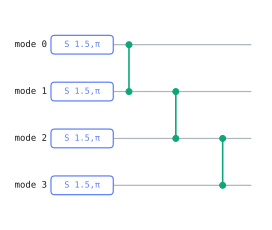

In [4]:
c = cv.Circuit(4)
for i in range(4):
    c.squeeze(1.5, phi=np.pi, mode=i)
for i, j in [(0, 1), (1, 2), (2, 3)]:
    c.cz(1.0, modes=(i, j))
c

## The elementary step: CZ + homodyne + feedforward

One-way MBQC is built from repeating a single elementary step: CZ-couple
an "input" mode to a fresh squeezed ancilla, measure the input mode, and
feed the outcome forward as a displacement on the ancilla -- which then
carries the teleported information onward as the next node in the
computation. (A full arbitrary single-mode Gaussian gate combines several
such steps with the measurement bases chosen to encode the desired
transformation; see Menicucci et al., PRL **97**, 110501 (2006) and Gu et
al., PRA **79**, 062318 (2009) for the complete construction -- reproducing
it exactly is beyond this demo's scope.)

The one piece we *can* verify directly: measuring the input mode's x
quadrature after the CZ coupling is untouched by that CZ (CZ only ever
modifies the *p* quadratures, in this library's convention -- see
`docs/conventions.md`), so it reads out the input's x information cleanly,
**independent of the ancilla's squeezing r**, while the projective
measurement leaves the ancilla in an exactly pure state (a general fact
for measuring part of a pure global state) whose remaining noise is set
entirely by the ancilla's own squeezing.

In [5]:
def teleport_step(alpha_in, r, seed=0):
    c = cv.Circuit(2)
    c.displace(alpha_in, mode=0)          # "input" mode
    c.squeeze(r, phi=np.pi, mode=1)       # fresh squeezed ancilla
    c.cz(1.0, modes=(0, 1))
    c.homodyne(0, angle=0.0, label="m0")
    c.displace(lambda m: m["m0"] / np.sqrt(2), mode=1)
    final_state, records = c._execute(seed=seed)
    return final_state.reduced([1]), records["m0"]

alpha_in = 0.8 - 0.4j
for r in [0.2, 1.0, 2.0, 3.0]:
    output_mode, outcome = teleport_step(alpha_in, r, seed=7)
    print(f"r={r}: purity={output_mode.purity():.6f}  mean={output_mode.mean}  "
          f"Var(x)={output_mode.cov[0, 0]:.4f}  Var(p)={output_mode.cov[1, 1]:.4f}")

r=0.2: purity=1.000000  mean=[1.2934 0.9145]  Var(x)=1.4918  Var(p)=0.6703
r=1.0: purity=1.000000  mean=[1.2934 0.9145]  Var(x)=7.3891  Var(p)=0.1353
r=2.0: purity=1.000000  mean=[1.2934 0.9145]  Var(x)=54.5982  Var(p)=0.0183
r=3.0: purity=1.000000  mean=[1.2934 0.9145]  Var(x)=403.4288  Var(p)=0.0025


Exactly as advertised: the output mean is identical at every r (the mean
transfer doesn't depend on the ancilla's squeezing at all), purity stays
at 1 to machine precision, and the output covariance is set directly by
the ancilla -- `Var(x) = exp(2r)`, `Var(p) = exp(-2r)`, matching a
momentum-squeezed ancilla exactly. The teleported node inherits the
ancilla's own squeezing.

Text(0.5, 1.0, "the teleported node's noise floor is set by the ancilla's squeezing")

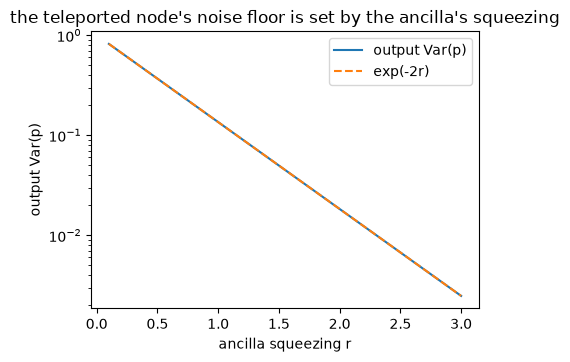

In [6]:
rs = np.linspace(0.1, 3.0, 25)
var_p = [teleport_step(alpha_in, r, seed=1)[0].cov[1, 1] for r in rs]

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.semilogy(rs, var_p, label="output Var(p)")
ax.semilogy(rs, np.exp(-2 * rs), "--", label="exp(-2r)")
ax.set_xlabel("ancilla squeezing r")
ax.set_ylabel("output Var(p)")
ax.legend()
ax.set_title("the teleported node's noise floor is set by the ancilla's squeezing")

## A larger cluster: entanglement across a square graph

A 4-mode square graph (a minimal 2-D cluster) has richer entanglement
structure than the linear chain -- every mode is connected to two
neighbours, so single-mode cuts show more entanglement than in the linear
case at the same squeezing.

In [7]:
square_adjacency = np.array([
    [0, 1, 0, 1],
    [1, 0, 1, 0],
    [0, 1, 0, 1],
    [1, 0, 1, 0],
], dtype=float)

square_cluster = cv.graph_state(square_adjacency, r=1.5)
linear_cluster = cv.graph_state(adjacency, r=1.5)  # from earlier, the 0-1-2-3 chain

print("square graph, log_negativity([0]):", cv.logarithmic_negativity(square_cluster, [0]))
print("linear chain, log_negativity([0]):", cv.logarithmic_negativity(linear_cluster, [0]))

square graph, log_negativity([0]): 5.828531925488922
linear chain, log_negativity([0]): 5.32897831365663
